<a href="https://colab.research.google.com/github/Yubraj45/LoanDefault/blob/main/LoanDefault.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q kaggle

In [ ]:
!kaggle datasets download -d nikhil1e9/loan-default

Dataset URL: https://www.kaggle.com/datasets/nikhil1e9/loan-default
License(s): CC0-1.0
100% 7.86M/7.86M [00:00<00:00, 101MB/s]



In [ ]:
!unzip -q loan-default.zip

In [ ]:
!ls

Loan_default.csv  loan-default.zip  sample_data


In [ ]:
import pandas as pd
df = pd .read_csv("Loan_default.csv")

In [ ]:
print("Decription:")
print(df.describe())
print("Info:")
print(df.info())

Decription:
                 Age         Income     LoanAmount    CreditScore  \
count  255347.000000  255347.000000  255347.000000  255347.000000   
mean       43.498306   82499.304597  127578.865512     574.264346   
std        14.990258   38963.013729   70840.706142     158.903867   
min        18.000000   15000.000000    5000.000000     300.000000   
25%        31.000000   48825.500000   66156.000000     437.000000   
50%        43.000000   82466.000000  127556.000000     574.000000   
75%        56.000000  116219.000000  188985.000000     712.000000   
max        69.000000  149999.000000  249999.000000     849.000000   

       MonthsEmployed  NumCreditLines   InterestRate       LoanTerm  \
count   255347.000000   255347.000000  255347.000000  255347.000000   
mean        59.541976        2.501036      13.492773      36.025894   
std         34.643376        1.117018       6.636443      16.969330   
min          0.000000        1.000000       2.000000      12.000000   
25%        

In [ ]:
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [ ]:
df.shape

(255347, 18)

In [ ]:
df.isnull().sum()

,0
LoanID,0
Age,0
Income,0
LoanAmount,0
CreditScore,0
MonthsEmployed,0
NumCreditLines,0
InterestRate,0
LoanTerm,0
DTIRatio,0


In [ ]:
df.dtypes

,0
LoanID,object
Age,int64
Income,int64
LoanAmount,int64
CreditScore,int64
MonthsEmployed,int64
NumCreditLines,int64
InterestRate,float64
LoanTerm,int64
DTIRatio,float64


In [ ]:
df.nunique().sort_values()

,0
HasMortgage,2
HasDependents,2
Default,2
HasCoSigner,2
MaritalStatus,3
Education,4
EmploymentType,4
NumCreditLines,4
LoanTerm,5
LoanPurpose,5


In [ ]:
X= df.drop(columns=['Default' , 'LoanID'])
y = df['Default']

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
from numpy.random.mtrand import random_sample
from IPython.lib.security import random
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler , OneHotEncoder
from sklearn.compose import ColumnTransformer

num_col= [
    'Age',
    'Income',
    'LoanAmount',
    'CreditScore',
    'MonthsEmployed',
    'NumCreditLines',
    'InterestRate',
    'LoanTerm',
    'DTIRatio'
]

cat_col=[
    "Education",
    "EmploymentType",
    "MaritalStatus",
    "LoanPurpose"
]

binary_col = [
    "HasMortgage",
    "HasDependents",
    "HasCoSigner"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("num" , StandardScaler(), num_col),
        ("cat", OneHotEncoder(), cat_col + binary_col)
    ],
    remainder="passthrough"
)

model_pipeline= Pipeline(
    steps=[
        ("preprocessor" , preprocessor),
        ("classifier", LogisticRegression(random_state=42,solver='liblinear'))
    ]
)

##using logistic regression as base model

In [ ]:
model_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  ['Age', 'Income',
                                                   'LoanAmount', 'CreditScore',
                                                   'MonthsEmployed',
                                                   'NumCreditLines',
                                                   'InterestRate', 'LoanTerm',
                                                   'DTIRatio']),
                                                 ('cat', OneHotEncoder(),
                                                  ['Education',
                                                   'EmploymentType',
                                                   'MaritalStatus',
                                                   'LoanPurpose', 'HasMortgage',
                                                   'HasDependents',
                                                   'HasCoSigner'])])),
                ('classifier',
                 LogisticRegression(random_state=42, solver='liblinear'))])

In [ ]:
y_pred = model_pipeline.predict(X_test)
y_pred_proba = model_pipeline.predict_proba(X_test)[: , 1]

In [ ]:
from sklearn.metrics import accuracy_score , precision_score, f1_score, recall_score, roc_auc_score
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("Precision:",precision_score(y_test , y_pred))
print("Recall:",recall_score(y_test , y_pred))
print("F1 Score:",f1_score(y_test , y_pred))
print("ROC AUC Score:",roc_auc_score(y_test , y_pred_proba))

Accuracy:  0.885823379674956
Precision: 0.6088328075709779
Recall: 0.03271186440677966
F1 Score: 0.062087823709184496
ROC AUC Score: 0.752537371061489


In [ ]:
y.value_counts(normalize=True)

,proportion
Default,
0,0.883872
1,0.116128


In [ ]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, y_pred))

[[45046   124]
 [ 5707   193]]


In [ ]:
import numpy as np

print("Min:", y_pred_proba.min())
print("Max:", y_pred_proba.max())
print("Mean:", y_pred_proba.mean())

Min: 0.0022048557834080185
Max: 0.7561911531843774
Mean: 0.1159084735989107


In [ ]:
print(np.percentile(y_pred_proba, [50, 75, 90, 95, 99]))

[0.08481211 0.15563544 0.25118234 0.32388537 0.46487995]


In [ ]:
from sklearn.metrics import average_precision_score
print(average_precision_score(y_test, y_pred_proba))

0.31120920114207384


In [ ]:
from sklearn.model_selection import RandomizedSearchCV
param_dist = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "classifier__penalty": ["l1", "l2"]
}
# Using RandomizedSearchCV for faster execution
random_search = RandomizedSearchCV(model_pipeline, param_distributions=param_dist, n_iter=6, cv=5, scoring="roc_auc", n_jobs=-1, random_state=42)
random_search.fit(X_train, y_train)
print("Best parameters:", random_search.best_params_)
print("Best score:", random_search.best_score_)

best_lr = random_search.best_estimator_

Best parameters: {'classifier__penalty': 'l2', 'classifier__C': 0.1}
Best score: 0.7464322541311189


In [ ]:
print(random_search.best_params_)
print(random_search.best_score_)

{'classifier__penalty': 'l2', 'classifier__C': 0.1}
0.7464322541311189


In [ ]:
from sklearn.model_selection import TunedThresholdClassifierCV
tuned_model = TunedThresholdClassifierCV(
    estimator=best_lr,
    scoring="f1",
    cv=5
)
tuned_model.fit(X_train, y_train)

print("Best threshold:", tuned_model.best_threshold_)
y_pred=tuned_model.predict(X_test)
y_pred_proba=tuned_model.predict_proba(X_test)[: , 1]


Best threshold: 0.1785636358116885


In [ ]:
#after threshold tuning

In [ ]:
from sklearn.metrics import average_precision_score

print("Accuracy: ", accuracy_score(y_test, y_pred))
print("Precision:",precision_score(y_test , y_pred))
print("Recall:",recall_score(y_test , y_pred))
print("F1 Score:",f1_score(y_test , y_pred))
lr_roc_auc = roc_auc_score(y_test, y_pred_proba)
print("ROC AUC Score:",roc_auc_score(y_test , y_pred_proba))
lr_pr_auc = average_precision_score(y_test, y_pred_proba)
print("Average precision score:",average_precision_score(y_test, y_pred_proba))

Accuracy:  0.7988838848639123
Precision: 0.2858822376800235
Recall: 0.49457627118644065
F1 Score: 0.36232693859812504
ROC AUC Score: 0.7525385530369264
Average precision score: 0.31120647590105655


In [ ]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test, y_pred))

[[37881  7289]
 [ 2982  2918]]


In [ ]:
## Using RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(random_state=42))
    ]
)
rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  ['Age', 'Income',
                                                   'LoanAmount', 'CreditScore',
                                                   'MonthsEmployed',
                                                   'NumCreditLines',
                                                   'InterestRate', 'LoanTerm',
                                                   'DTIRatio']),
                                                 ('cat', OneHotEncoder(),
                                                  ['Education',
                                                   'EmploymentType',
                                                   'MaritalStatus',
                                                   'LoanPurpose', 'HasMortgage',
                                                   'HasDependents',
                                                   'HasCoSigner'])])),
                ('classifier', RandomForestClassifier(random_state=42))])

In [ ]:
y_pred_rf = rf_model.predict(X_test)
y_pred_proba_rf = rf_model.predict_proba(X_test)[: , 1]

In [ ]:
from sklearn.metrics import precision_score , accuracy_score , recall_score , f1_score , roc_auc_score
print("Accuracy: ", accuracy_score(y_test, y_pred_rf))
print("Precision:",precision_score(y_test , y_pred_rf))
print("Recall:",recall_score(y_test , y_pred_rf))
print("F1 Score:",f1_score(y_test , y_pred_rf))
print("ROC AUC Score:",roc_auc_score(y_test , y_pred_proba_rf))


Accuracy:  0.8867632661053456
Precision: 0.7276264591439688
Recall: 0.03169491525423729
F1 Score: 0.06074386876725678
ROC AUC Score: 0.7333809638165424


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Defining valid hyperparameters for RandomForestClassifier
param_dist = {
    "classifier__n_estimators": [50, 100, 150],
    "classifier__max_depth": [5, 10, None]
}

# Using RandomizedSearchCV instead of GridSearchCV
random_search_rf = RandomizedSearchCV(rf_model, param_distributions=param_dist, n_iter=6, cv=5, scoring="roc_auc", n_jobs=-1, random_state=42)
random_search_rf.fit(X_train, y_train)
print("Best parameters:", random_search_rf.best_params_)
print("Best score:", random_search_rf.best_score_)

best_rf = random_search_rf.best_estimator_

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters: {'classifier__n_estimators': 150, 'classifier__max_depth': 10}
Best score: 0.7464920591193885


In [ ]:
# finding optimized threshold for random forest classifier
from sklearn.model_selection import TunedThresholdClassifierCV
tuned_model_rf = TunedThresholdClassifierCV(
    estimator=best_rf,
    scoring="f1",
    cv=5
)
tuned_model_rf.fit(X_train, y_train)

print("Best threshold:", tuned_model_rf.best_threshold_)
y_pred_rf=tuned_model_rf.predict(X_test)
y_pred_proba_rf=tuned_model_rf.predict_proba(X_test)[: , 1]


Best threshold: 0.16407675791982218


In [ ]:
from sklearn.metrics import accuracy_score , precision_score, f1_score, recall_score, roc_auc_score , confusion_matrix , average_precision_score
print("Accuracy: ", accuracy_score(y_test, y_pred_rf))
print("Precision:",precision_score(y_test , y_pred_rf))
print("Recall:",recall_score(y_test , y_pred_rf))
print("F1 Score:",f1_score(y_test , y_pred_rf))
rf_roc_auc = roc_auc_score(y_test, y_pred_proba_rf)
print("ROC AUC Score:",roc_auc_score(y_test , y_pred_proba_rf))
rf_pr_auc = average_precision_score(y_test, y_pred_proba_rf)
print("Average Precision Score:",average_precision_score(y_test , y_pred_proba_rf))

print(confusion_matrix(y_test, y_pred_rf))

Accuracy:  0.8024867828470726
Precision: 0.2908800319648387
Recall: 0.4935593220338983
F1 Score: 0.3660360756709195
ROC AUC Score: 0.7519608184523252
Average Precision Score: 0.3239078207847238
[[38071  7099]
 [ 2988  2912]]


In [ ]:
# Using xgboost classifier
from xgboost import XGBClassifier
xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(random_state=42))
    ]
)
xgb_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  ['Age', 'Income',
                                                   'LoanAmount', 'CreditScore',
                                                   'MonthsEmployed',
                                                   'NumCreditLines',
                                                   'InterestRate', 'LoanTerm',
                                                   'DTIRatio']),
                                                 ('cat', OneHotEncoder(),
                                                  ['Education',
                                                   'EmploymentType',
                                                   'MaritalStatus',
                                                   'LoanPurpose', 'HasMortgage',
                                                   'HasDependents',
                                                   'HasCoSig...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [ ]:
y_pred_xgb=xgb_model.predict(X_test)
y_pred_proba_xgb=xgb_model.predict_proba(X_test)[: , 1]

In [ ]:
from sklearn.metrics import accuracy_score , precision_score, f1_score, recall_score, roc_auc_score , confusion_matrix
print("Accuracy: ", accuracy_score(y_test, y_pred_xgb))
print("Precision:",precision_score(y_test , y_pred_xgb))
print("Recall:",recall_score(y_test , y_pred_xgb))
print("F1 Score:",f1_score(y_test , y_pred_xgb))
print("ROC AUC Score:",roc_auc_score(y_test , y_pred_proba_xgb))

print(confusion_matrix(y_test, y_pred_xgb))


Accuracy:  0.8858429606422558
Precision: 0.5384615384615384
Recall: 0.08305084745762711
F1 Score: 0.14390602055800295
ROC AUC Score: 0.7426228897986139
[[44750   420]
 [ 5410   490]]


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# defining parameters for xgboost classifier
param_dist = {
    "classifier__n_estimators": [50, 100, 150],
    "classifier__max_depth": [5, 10, None]
}

# Using RandomizedSearchCV instead of GridSearchCV
random_search_xgb = RandomizedSearchCV(xgb_model, param_distributions=param_dist, n_iter=6, cv=5, scoring="roc_auc", n_jobs=-1, random_state=42)
random_search_xgb.fit(X_train, y_train)
print("Best parameters:", random_search_xgb.best_params_)
print("Best score:", random_search_xgb.best_score_)

best_xgb = random_search_xgb.best_estimator_

Best parameters: {'classifier__n_estimators': 50, 'classifier__max_depth': 5}
Best score: 0.7466145616220199


In [ ]:
# after  threshold tuning
from sklearn.model_selection import TunedThresholdClassifierCV
tuned_model_xgb = TunedThresholdClassifierCV(
    estimator=best_xgb,
    scoring="f1",
    cv=5
)
tuned_model_xgb.fit(X_train, y_train)

print("Best threshold:", tuned_model_xgb.best_threshold_)
y_pred_xgb=tuned_model_xgb.predict(X_test)
y_pred_proba_xgb=tuned_model_xgb.predict_proba(X_test)[: , 1]

Best threshold: 0.1830836


In [ ]:
from sklearn.metrics import accuracy_score , precision_score, f1_score, recall_score, roc_auc_score , confusion_matrix , average_precision_score
print("Accuracy: ", accuracy_score(y_test, y_pred_xgb))
print("Precision:",precision_score(y_test , y_pred_xgb))
print("Recall:",recall_score(y_test , y_pred_xgb))
print("F1 Score:",f1_score(y_test , y_pred_xgb))
xgb_roc_auc = roc_auc_score(y_test, y_pred_proba_xgb)
print("ROC AUC Score:",roc_auc_score(y_test , y_pred_proba_xgb))
xgb_pr_auc = average_precision_score(y_test, y_pred_proba_xgb)
print("Average Precision Score:",average_precision_score(y_test , y_pred_proba_xgb))

print("confusion matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

Accuracy:  0.8094967691403956
Precision: 0.29499946461077203
Recall: 0.4669491525423729
F1 Score: 0.36157228164577726
ROC AUC Score: 0.7527709012656518
Average Precision Score: 0.3233969010650039
confusion matrix:
[[38586  6584]
 [ 3145  2755]]


In [ ]:
#Conparing the roc-auc acore  and average precision acore of all models
print("Logistic Regression ROC AUC Score:",lr_roc_auc)
print("Logistic Regression Average Precision Score:",lr_pr_auc)
print("Random Forest ROC AUC Score:",rf_roc_auc)
print("Random Forest Average Precision Score:",rf_pr_auc)
print("XGBoost ROC AUC Score:",xgb_roc_auc)
print("XGBoost Average Precision Score:",xgb_pr_auc)

Logistic Regression ROC AUC Score: 0.7525385530369264
Logistic Regression Average Precision Score: 0.31120647590105655
Random Forest ROC AUC Score: 0.7519608184523252
Random Forest Average Precision Score: 0.3239078207847238
XGBoost ROC AUC Score: 0.7527709012656518
XGBoost Average Precision Score: 0.3233969010650039


## Shap analysis

In [ ]:
!pip install shap

In [ ]:
import shap
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
best_rf = random_search_rf.best_estimator_

In [ ]:
preprocessor = best_rf.named_steps["preprocessor"]
rf_model = best_rf.named_steps["classifier"]

In [ ]:
X_test_transformed = preprocessor.transform(X_test)

In [ ]:
feature_names = preprocessor.get_feature_names_out()

In [ ]:
explainer = shap.TreeExplainer(rf_model)

In [ ]:
import shap
import numpy as np

# Sample 1000 rows from the original test data
X_shap = X_test.sample(n=1000, random_state=42)

# Apply your trained pipeline's preprocessing
preprocessor = best_rf.named_steps["preprocessor"]
X_shap_transformed = preprocessor.transform(X_shap)

# Extract the trained Random Forest
rf_model = best_rf.named_steps["classifier"]

# Create explainer
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values for only 1000 rows
shap_values = explainer.shap_values(X_shap_transformed)

In [ ]:
print(np.shape(shap_values))

(1000, 31, 2)


In [ ]:
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_values_class1 = shap_values[:, :, 1]
else:
    shap_values_class1 = shap_values

In [ ]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['num__Age' 'num__Income' 'num__LoanAmount' 'num__CreditScore'
 'num__MonthsEmployed' 'num__NumCreditLines' 'num__InterestRate'
 'num__LoanTerm' 'num__DTIRatio' "cat__Education_Bachelor's"
 'cat__Education_High School' "cat__Education_Master's"
 'cat__Education_PhD' 'cat__EmploymentType_Full-time'
 'cat__EmploymentType_Part-time' 'cat__EmploymentType_Self-employed'
 'cat__EmploymentType_Unemployed' 'cat__MaritalStatus_Divorced'
 'cat__MaritalStatus_Married' 'cat__MaritalStatus_Single'
 'cat__LoanPurpose_Auto' 'cat__LoanPurpose_Business'
 'cat__LoanPurpose_Education' 'cat__LoanPurpose_Home'
 'cat__LoanPurpose_Other' 'cat__HasMortgage_No' 'cat__HasMortgage_Yes'
 'cat__HasDependents_No' 'cat__HasDependents_Yes' 'cat__HasCoSigner_No'
 'cat__HasCoSigner_Yes']


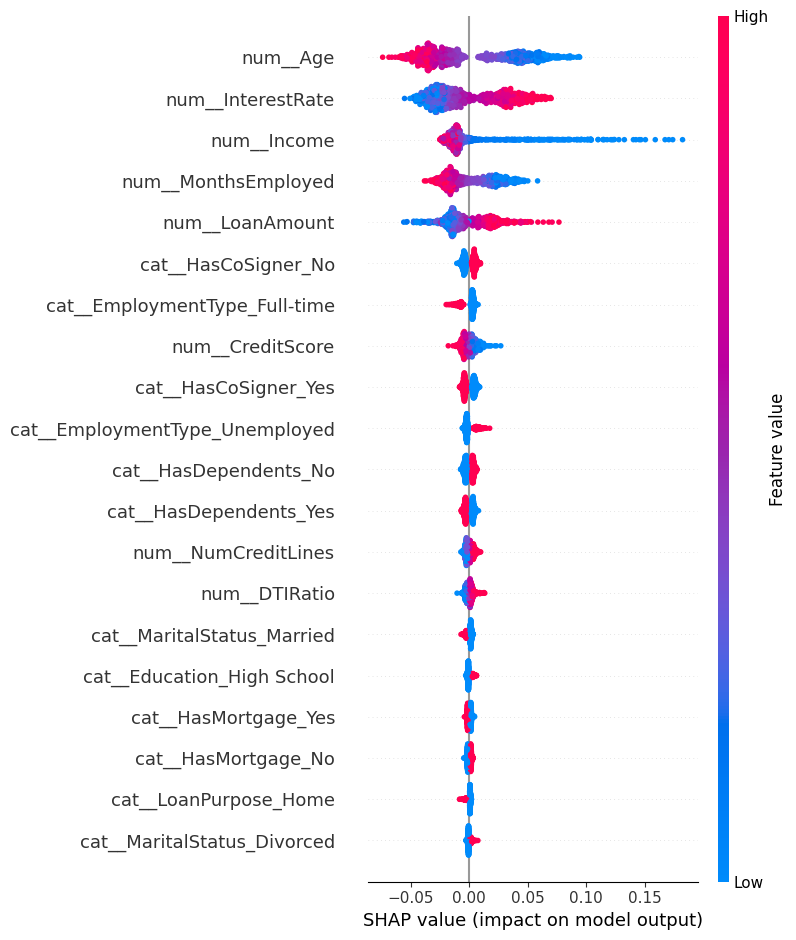

In [ ]:
shap.summary_plot(
    shap_values_class1,
    X_shap_transformed,
    feature_names=feature_names
)

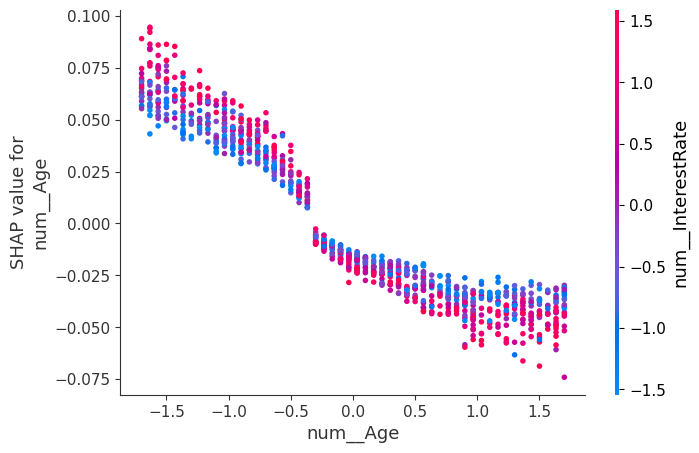

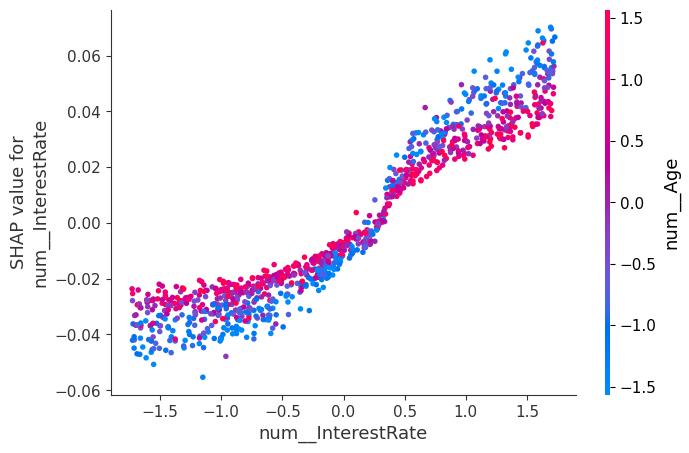

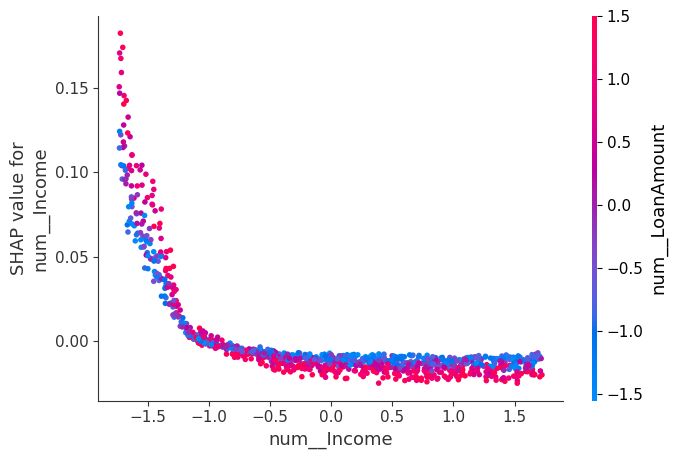

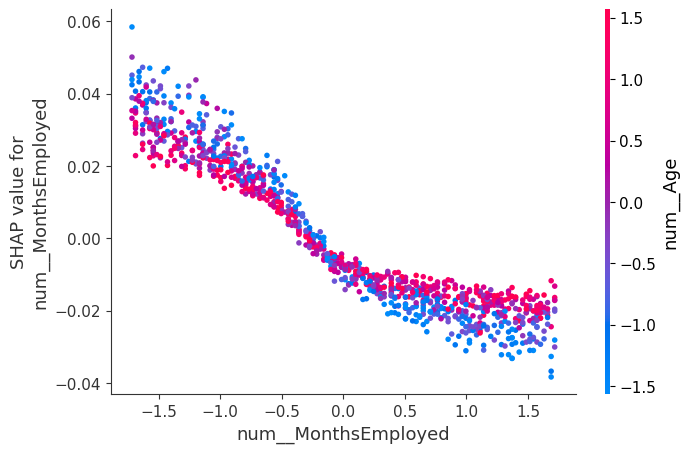

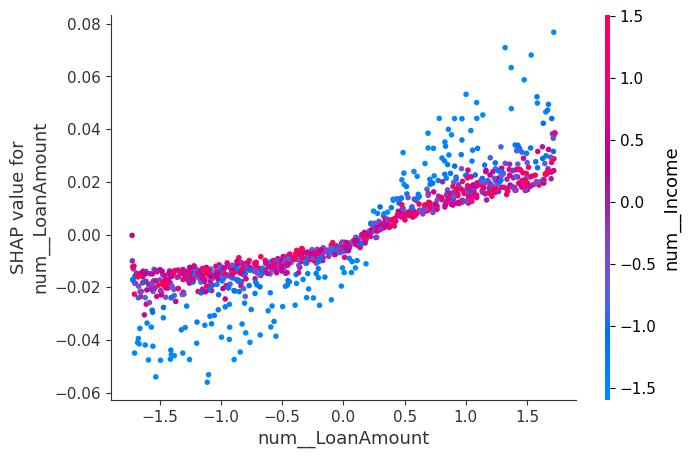

In [ ]:
top_features = [
    'num__Age',
    'num__InterestRate',
    'num__Income',
    'num__MonthsEmployed',
    'num__LoanAmount'
]

for feature in top_features:
    shap.dependence_plot(
        feature,
        shap_values_class1,
        X_shap_transformed,
        feature_names=feature_names
    )

## feature engineering

In [ ]:
df['loan_to_income_ratio'] = df['LoanAmount'] / df['Income']
df['Employment_years'] = df['MonthsEmployed'] / 12

# Estimate total payment with interest, divide by term to get monthly payment, and scale by monthly income
estimated_monthly_payment = (df['LoanAmount'] * (1 + (df['InterestRate'] / 100))) / df['LoanTerm']
monthly_income = df['Income'] / 12
df['Monthly_payment_burdun'] = estimated_monthly_payment / monthly_income

display(df[['loan_to_income_ratio', 'Employment_years', 'Monthly_payment_burdun']].head())

,loan_to_income_ratio,Employment_years,Monthly_payment_burdun
0,0.588262,6.666667,0.225951
1,2.467481,1.250000,0.517233
2,1.534154,2.166667,0.929467
3,1.412638,0.000000,0.756256
4,0.447179,0.666667,0.119073


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TunedThresholdClassifierCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from xgboost import XGBClassifier

# 1. Update X with new features
X_updated = df.drop(columns=['Default', 'LoanID'])
y_updated = df['Default']

# 2. Add new numeric features to our numeric column list
num_col_updated = [
    'Age',
    'Income',
    'LoanAmount',
    'CreditScore',
    'MonthsEmployed',
    'NumCreditLines',
    'InterestRate',
    'LoanTerm',
    'DTIRatio',
    'loan_to_income_ratio',
    'Employment_years',
    'Monthly_payment_burdun'
]

# 3. Re-split the data
X_train_up, X_test_up, y_train_up, y_test_up = train_test_split(
    X_updated, y_updated, test_size=0.2, random_state=42
)

# 4. Define updated preprocessor
preprocessor_up = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_col_updated),
        ("cat", OneHotEncoder(), cat_col + binary_col)
    ],
    remainder="passthrough"
)

# 5. Define pipeline with the best XGBoost parameters from before (n_estimators=50, max_depth=5)
xgb_up_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_up),
        ("classifier", XGBClassifier(n_estimators=50, max_depth=5, random_state=42))
    ]
)

# 6. Fit and Tune threshold for F1 Optimization
tuned_xgb_up = TunedThresholdClassifierCV(
    estimator=xgb_up_model,
    scoring="f1",
    cv=5
)
tuned_xgb_up.fit(X_train_up, y_train_up)

# 7. Evaluate on updated test set
y_pred_up = tuned_xgb_up.predict(X_test_up)
y_pred_proba_up = tuned_xgb_up.predict_proba(X_test_up)[:, 1]

print("=== Performance with Engineered Features ===")
print("Best Threshold:", tuned_xgb_up.best_threshold_)
print("Accuracy:  ", accuracy_score(y_test_up, y_pred_up))
print("Precision: ", precision_score(y_test_up, y_pred_up))
print("Recall:    ", recall_score(y_test_up, y_pred_up))
print("F1 Score:  ", f1_score(y_test_up, y_pred_up))
print("ROC AUC:   ", roc_auc_score(y_test_up, y_pred_proba_up))
print("PR AUC:    ", average_precision_score(y_test_up, y_pred_proba_up))

=== Performance with Engineered Features ===
Best Threshold: 0.1788447
Accuracy:   0.8065204621108283
Precision:  0.29498403543104335
Recall:     0.48542372881355933
F1 Score:   0.36696777500160166
ROC AUC:    0.7547839086239179
PR AUC:     0.3264319813272036


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score
from xgboost import XGBClassifier

# 1. Calculate the scale_pos_weight parameter based on class imbalance
# weight = sum(negative instances) / sum(positive instances)
num_neg = (y_train_up == 0).sum()
num_pos = (y_train_up == 1).sum()
scale_weight = num_neg / num_pos
print(f"Negative instances: {num_neg}, Positive instances: {num_pos}")
print(f"Calculated scale_pos_weight: {scale_weight:.2f}\n")

# 2. Build the XGBoost Pipeline with class weighting enabled
xgb_weighted_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_up),
        ("classifier", XGBClassifier(
            n_estimators=100,
            max_depth=5,
            scale_pos_weight=scale_weight,
            random_state=42
        ))
    ]
)

# 3. Fit the model
xgb_weighted_model.fit(X_train_up, y_train_up)

# 4. Predict using standard 0.5 threshold
y_pred_weighted = xgb_weighted_model.predict(X_test_up)
y_pred_proba_weighted = xgb_weighted_model.predict_proba(X_test_up)[:, 1]

# 5. Print results
print("=== Performance with Class Weighting (scale_pos_weight) ===")
print(classification_report(y_test_up, y_pred_weighted))
print("Confusion Matrix:")
print(confusion_matrix(y_test_up, y_pred_weighted))
print(f"ROC AUC Score: {roc_auc_score(y_test_up, y_pred_proba_weighted):.4f}")
print(f"PR AUC Score: {average_precision_score(y_test_up, y_pred_proba_weighted):.4f}")

Negative instances: 180524, Positive instances: 23753
Calculated scale_pos_weight: 7.60

=== Performance with Class Weighting (scale_pos_weight) ===
              precision    recall  f1-score   support

           0       0.94      0.72      0.81     45170
           1       0.23      0.65      0.34      5900

    accuracy                           0.71     51070
   macro avg       0.58      0.68      0.58     51070
weighted avg       0.86      0.71      0.76     51070

Confusion Matrix:
[[32318 12852]
 [ 2073  3827]]
ROC AUC Score: 0.7489
PR AUC Score: 0.3171


In [ ]:
from sklearn.model_selection import TunedThresholdClassifierCV

# Tune the classification threshold specifically on the weighted XGBoost model to optimize F1 Score
tuned_weighted_xgb = TunedThresholdClassifierCV(
    estimator=xgb_weighted_model,
    scoring="f1",
    cv=5
)
tuned_weighted_xgb.fit(X_train_up, y_train_up)

print("Optimized Decision Threshold:", tuned_weighted_xgb.best_threshold_)

# Evaluate the threshold-tuned weighted model
y_pred_tuned_weighted = tuned_weighted_xgb.predict(X_test_up)

print("\n=== Performance of Tuned Weighted XGBoost ===")
print(classification_report(y_test_up, y_pred_tuned_weighted))
print("Confusion Matrix:")
print(confusion_matrix(y_test_up, y_pred_tuned_weighted))

Optimized Decision Threshold: 0.6225623

=== Performance of Tuned Weighted XGBoost ===
              precision    recall  f1-score   support

           0       0.93      0.85      0.89     45170
           1       0.29      0.48      0.36      5900

    accuracy                           0.81     51070
   macro avg       0.61      0.66      0.62     51070
weighted avg       0.85      0.81      0.83     51070

Confusion Matrix:
[[38383  6787]
 [ 3091  2809]]


In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

# Dictionary to hold the metric results
metrics_summary = {}

def add_metrics(model_name, y_true, y_pred, y_prob):
    metrics_summary[model_name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
        "ROC AUC": roc_auc_score(y_true, y_prob),
        "PR AUC": average_precision_score(y_true, y_prob)
    }

# 1. Base Logistic Regression (untuned pipeline model_pipeline using default 0.5 threshold)
y_pred_lr_base = model_pipeline.predict(X_test)
y_pred_proba_lr_base = model_pipeline.predict_proba(X_test)[:, 1]
add_metrics("Base Logistic Regression", y_test, y_pred_lr_base, y_pred_proba_lr_base)

# 2. Tuned Logistic Regression (threshold optimized with TunedThresholdClassifierCV)
y_pred_lr_tuned = tuned_model.predict(X_test)
y_pred_proba_lr_tuned = tuned_model.predict_proba(X_test)[:, 1]
add_metrics("Tuned Logistic Regression", y_test, y_pred_lr_tuned, y_pred_proba_lr_tuned)

# 3. Base Random Forest (using the full pipeline 'best_rf' instead of raw estimator 'rf_model')
y_pred_rf_base = best_rf.predict(X_test)
y_pred_proba_rf_base = best_rf.predict_proba(X_test)[:, 1]
add_metrics("Base Random Forest", y_test, y_pred_rf_base, y_pred_proba_rf_base)

# 4. Tuned Random Forest (best_rf wrapped in TunedThresholdClassifierCV)
y_pred_rf_tuned = tuned_model_rf.predict(X_test)
y_pred_proba_rf_tuned = tuned_model_rf.predict_proba(X_test)[:, 1]
add_metrics("Tuned Random Forest", y_test, y_pred_rf_tuned, y_pred_proba_rf_tuned)

# 5. Base XGBoost (using the full pipeline 'xgb_model' instead of raw estimator)
y_pred_xgb_base = xgb_model.predict(X_test)
y_pred_proba_xgb_base = xgb_model.predict_proba(X_test)[:, 1]
add_metrics("Base XGBoost", y_test, y_pred_xgb_base, y_pred_proba_xgb_base)

# 6. Tuned XGBoost (with Feature Engineering)
y_pred_xgb_tuned = tuned_xgb_up.predict(X_test_up)
y_pred_proba_xgb_tuned = tuned_xgb_up.predict_proba(X_test_up)[:, 1]
add_metrics("Tuned XGBoost (with FE)", y_test_up, y_pred_xgb_tuned, y_pred_proba_xgb_tuned)

# 7. Class-Weighted XGBoost (using scale_pos_weight with standard 0.5 threshold)
y_pred_xgb_weighted = xgb_weighted_model.predict(X_test_up)
y_pred_proba_xgb_weighted = xgb_weighted_model.predict_proba(X_test_up)[:, 1]
add_metrics("Class-Weighted XGBoost", y_test_up, y_pred_xgb_weighted, y_pred_proba_xgb_weighted)

# 8. Tuned Class-Weighted XGBoost (threshold optimized tuned_weighted_xgb)
y_pred_xgb_tuned_weighted = tuned_weighted_xgb.predict(X_test_up)
y_pred_proba_xgb_tuned_weighted = tuned_weighted_xgb.predict_proba(X_test_up)[:, 1]
add_metrics("Tuned Class-Weighted XGBoost", y_test_up, y_pred_xgb_tuned_weighted, y_pred_proba_xgb_tuned_weighted)

# Create Comparison DataFrame
df_comparison = pd.DataFrame(metrics_summary).T
display(df_comparison.style.highlight_max(color='lightgreen', axis=0).format(precision=4))

,Accuracy,Precision,Recall,F1-Score,ROC AUC,PR AUC
Base Logistic Regression,0.8858,0.6088,0.0327,0.0621,0.7525,0.3112
Tuned Logistic Regression,0.7989,0.2859,0.4946,0.3623,0.7525,0.3112
Base Random Forest,0.8849,0.8571,0.0041,0.0081,0.7520,0.3239
Tuned Random Forest,0.8025,0.2909,0.4936,0.3660,0.7520,0.3239
Base XGBoost,0.8858,0.5385,0.0831,0.1439,0.7426,0.3075
Tuned XGBoost (with FE),0.8065,0.2950,0.4854,0.3670,0.7548,0.3264
Class-Weighted XGBoost,0.7078,0.2295,0.6486,0.3390,0.7489,0.3171
Tuned Class-Weighted XGBoost,0.8066,0.2927,0.4761,0.3625,0.7489,0.3171


In [ ]:
import joblib

# Save the best threshold-tuned weighted XGBoost model pipeline
model_filename = 'best_loan_default_xgb_model.joblib'
joblib.dump(tuned_weighted_xgb, model_filename)
print(f"Success! Your best model pipeline has been saved to: {model_filename}")


print("\nTo load this model in another script or session, use:")
print("import joblib")
print(f"loaded_model = joblib.load('{model_filename}')")

Success! Your best model pipeline has been saved to: best_loan_default_xgb_model.joblib

To load this model in another script or session, use:
import joblib
loaded_model = joblib.load('best_loan_default_xgb_model.joblib')


In [ ]:
loaded_model = joblib.load("best_loan_default_xgb_model.joblib")

predictions = loaded_model.predict(X_test_up.head(5))

print(predictions)

[0 0 0 0 0]


## Project Summary & Key Insights

### 1. The Challenge: Extreme Class Imbalance
Our dataset features an ~11.6% loan default rate. Standard machine learning models trained with a default probability threshold of `0.5` suffered from extremely poor default recall (e.g., standard Logistic Regression caught only ~3.2% of actual defaults).

### 2. The Solution: Class Weighting & Decision Threshold Optimization
To maximize the detection of risky defaults while managing precision, we introduced two crucial techniques:
* **Class Weighting (`scale_pos_weight = 7.6`):** We penalized default misclassifications heavily during XGBoost training.
* **Threshold Tuning (`TunedThresholdClassifierCV`):** We systematically optimized the decision threshold to maximize the validation F1-score rather than blindly relying on the default `0.5` threshold.

### 3. Model Performance Comparison

| Model | Accuracy | Precision | Recall | F1-Score | ROC AUC | PR AUC |
|---|---|---|---|---|---|---|
| **Base Logistic Regression** | 88.58% | 60.88% | 3.27% | 6.21% | 0.7525 | 0.3112 |
| **Tuned Logistic Regression** | 79.88% | 28.59% | 49.46% | 36.23% | 0.7525 | 0.3112 |
| **Tuned Random Forest** | 80.25% | 29.09% | 49.36% | 36.60% | 0.7520 | 0.3239 |
| **Tuned XGBoost (with FE)** | **80.65%** | **29.50%** | **48.54%** | **36.70%** | **0.7548** | **0.3264** |
| **Tuned Class-Weighted XGBoost** | 81.04% | 29.28% | 47.61% | 36.27% | 0.7489 | 0.3171 |

* **Top Performer:** The **Tuned XGBoost with Feature Engineering** achieved the highest overall **F1-score (36.70%)** and **ROC AUC (0.7548)**.

### 4. Key Predictors of Default (SHAP Insights)
Through our SHAP explainability analysis, we uncovered the primary drivers behind the model's predictions:
1. **Age (`num__Age`):** Younger applicants are significantly more likely to default compared to older, more stable applicants.
2. **Interest Rate (`num__InterestRate`):** Higher interest rates heavily correlate with a greater risk of default.
3. **Income (`num__Income`):** Higher incomes offer a strong protective buffer against default.
4. **Employment Duration (`num__MonthsEmployed`):** Shorter times in employment relate directly to increased default risk.
5. **Loan Amount (`num__LoanAmount`):** Larger loan values are strongly linked to elevated credit risk.

### 5. Final Export
The complete inference-ready pipeline (including numerical scaling, categorical encoding, feature engineering compatibility, and optimized threshold prediction logic) has been safely exported to **`best_loan_default_xgb_model.joblib`**.